# 10 · Capstone on a Real Case: Visual Defect Inspection

Every notebook so far used data generated in the notebook or bundled with a library, so the results were exact and the runs were short. This capstone uses **real photographs from a real production line**, and it is run the way a team would tackle a data-science competition: a written brief, a metric fixed in advance, a test set that stays locked until the very end, and a leaderboard of every attempt.

**The case.** At the end of a manufacturing line, each finished blade is photographed before it is packed. Today a human inspector looks at every photo and sorts the blade into one of three bins:

| Class | Meaning | What happens to the part |
|---|---|---|
| **Good** | no visible defect | shipped |
| **Nick** | a small dent or chip, usually on an edge | rejected |
| **Scratch** | a thin line scored into the surface | rejected |

Automating this check is one of the most common computer-vision jobs in industry: the camera never gets tired, every decision is logged, and the inspector's time goes to the doubtful cases only. The catch is the one you meet in almost every real project: **very little labelled data** (400 photos, only 48 of them nicks), defects that cover a tiny fraction of the image, and a cost structure where letting a bad part through is far worse than rejecting a good one.

**The data.** The photos are the *GKN Blade Surface Defect Dataset*, published by Qianyu Zhou (University of Connecticut) on Mendeley Data in 2023, doi:[10.17632/3bh998k78g.1](https://doi.org/10.17632/3bh998k78g.1), under the [Creative Commons Attribution 4.0 (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/) licence, which allows reuse, including commercial reuse, as long as the source is credited. The notebook downloads them from that original publication, not from a copy (details in section 2).

What you will do, and which earlier notebook each step leans on:

| Section | Step | Builds on |
|---|---|---|
| 1-3 | the brief, the data, a first look | |
| 4 | a locked test set and cross-validation | 03 (train/dev/test) |
| 5 | baselines: majority class and hand-made image features | 03 (always beat a baseline) |
| 6 | a CNN trained from scratch | 04 |
| 7-8 | transfer learning: frozen features, then fine-tuning with augmentation | 04 (transfer learning, augmentation, ResNet) |
| 9 | ensembling and test-time augmentation | 03 |
| 10 | turning probabilities into an accept/reject decision | 09 (precision and recall) |
| 11 | opening the test set: the final leaderboard | |
| 12 | where the model looks (Grad-CAM) and what it gets wrong | 03 (error analysis) |
| 13 | from notebook to production line | |

It runs on a CPU. Unlike the other modules it needs two downloads the first time: the photos (about 80 MB) and the weights of a network pre-trained on ImageNet (about 45 MB, via `torchvision`). Both are cached, so later runs start immediately.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, json, time, hashlib, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, confusion_matrix

torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = False
CLASSES = ["Good", "Nick", "Scratch"]

## 1. The brief

Before touching the data, write down how success will be measured. Changing the metric after seeing results is the easiest way to fool yourself.

* **Task:** classify each photo as Good, Nick or Scratch.
* **Primary metric: macro-F1.** The F1 score (harmonic mean of precision and recall, notebook 09) is computed for each class and the three are averaged with equal weight. Plain accuracy would reward a model that ignores the rare Nick class: with half the photos being Good, "always Good" already scores about 50 %.
* **Operational metrics**, because the line only needs a yes/no decision in the end:
  * **escape rate**: share of defective parts that are passed as Good (the expensive mistake: a customer receives a damaged part);
  * **false-reject rate**: share of good parts sent to the reject bin (the cheaper mistake: a part is re-inspected or scrapped).
* **Rules:** a stratified 25 % of the photos is set aside as the **test set** and is not looked at until section 11. Every choice before that (model, resolution, threshold) is made with **5-fold cross-validation** on the remaining 75 %, which we call the development set.

Competition platforms work the same way: the score you see while you work is computed on data you are allowed to tune on, and the final ranking uses data nobody has seen. Teams that tune against the visible score too eagerly drop places when the hidden one is revealed.

## 2. The data

The photos are the **GKN Blade Surface Defect Dataset** published by Qianyu Zhou on Mendeley Data (2023, doi:[10.17632/3bh998k78g.1](https://doi.org/10.17632/3bh998k78g.1)) under the **Creative Commons Attribution 4.0** licence, which allows reuse with credit. The same files are mirrored on several public dataset hubs; we download them from the original publication. The next cell asks the repository for the list of files, downloads each photo once, and checks its SHA-256 fingerprint against the one the repository publishes, so a corrupted or altered file stops the notebook instead of silently changing the results.

In [2]:
API = "https://data.mendeley.com/public-api/datasets/3bh998k78g"
CACHE = os.path.expanduser("~/.cache/nn1001/gkn_blades")      # shared by every run of this notebook

def get(url):
    req = urllib.request.Request(url, headers={"User-Agent": "nn1001-course/1.0"})
    with urllib.request.urlopen(req, timeout=60) as r:
        return r.read()

def fetch(f, folders):
    path = os.path.join(CACHE, folders[f["folder_id"]], f["filename"])
    if not os.path.exists(path):
        data = get(f["content_details"]["download_url"])
        if hashlib.sha256(data).hexdigest() != f["content_details"]["sha256_hash"]:
            raise ValueError(f"checksum mismatch for {f['filename']}")
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with open(path, "wb") as out:
            out.write(data)
    return path

meta = json.loads(get(API))
folders = {d["id"]: d["name"] for d in json.loads(get(API + "/folders/1"))}
t0 = time.time()
with ThreadPoolExecutor(8) as pool:
    paths = list(pool.map(lambda f: fetch(f, folders), meta["files"]))
print(f"{meta['name']} (version {meta['version']}), licence: {meta['data_licence']['short_name']}")
print(f"{len(paths)} photos ready in {CACHE} ({time.time() - t0:.0f} s)")

GKN Blade Surface Defect Dataset (version 1), licence: CC BY 4.0
400 photos ready in /home/patito/.cache/nn1001/gkn_blades (0 s)


## 3. A first look

Count the classes, check the image sizes, and look at the photos with your own eyes before training anything.

Good      203 photos (51%)
Nick       48 photos (12%)
Scratch   149 photos (37%)
image width 892-1430 px, height 847-1631 px
accuracy of always answering 'Good': 50.7%


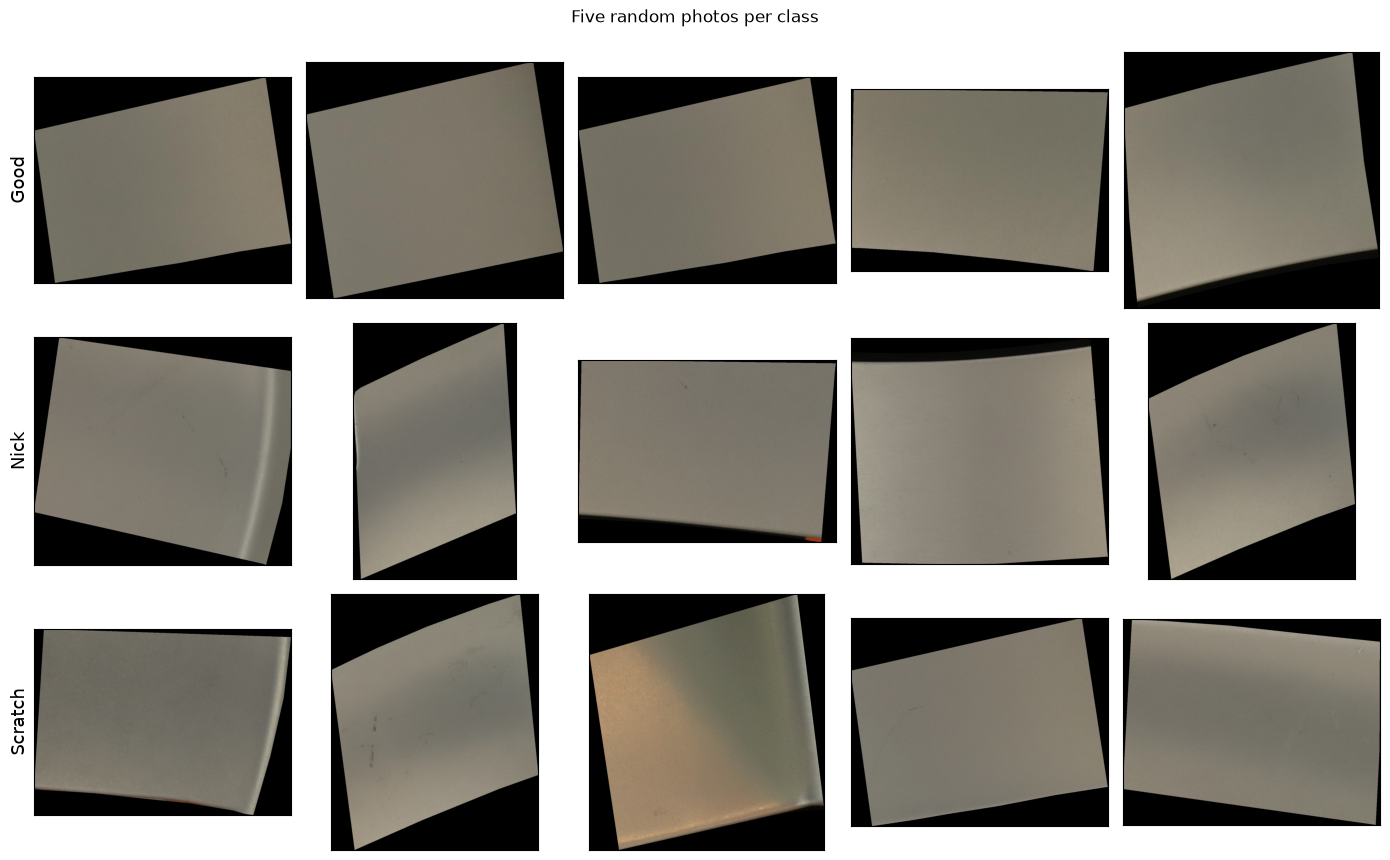

In [3]:
files = sorted(paths)
labels = np.array([CLASSES.index(os.path.basename(os.path.dirname(p))) for p in files])
sizes = np.array([Image.open(p).size for p in files])
for c, name in enumerate(CLASSES):
    print(f"{name:8s} {np.sum(labels == c):4d} photos ({np.mean(labels == c):.0%})")
print(f"image width {sizes[:, 0].min()}-{sizes[:, 0].max()} px, height {sizes[:, 1].min()}-{sizes[:, 1].max()} px")
print(f"accuracy of always answering 'Good': {np.mean(labels == 0):.1%}")

fig, axes = plt.subplots(3, 5, figsize=(14, 8.6))
rng = np.random.default_rng(1)
for c, name in enumerate(CLASSES):
    for k, i in enumerate(rng.choice(np.where(labels == c)[0], 5, replace=False)):
        ax = axes[c, k]; ax.imshow(Image.open(files[i])); ax.set_xticks([]); ax.set_yticks([])
        if k == 0: ax.set_ylabel(name, fontsize=13)
plt.suptitle("Five random photos per class", y=0.995); plt.tight_layout(); plt.show()

Three things stand out, and each one shapes the rest of the notebook:

1. **The classes are imbalanced**: about half the photos are Good and only one in eight is a Nick. The training loss will weight classes inversely to their frequency, and the metric is macro-F1.
2. **The photos are large (roughly 850 to 1,650 pixels a side) but the defects are tiny.** A nick is a few dozen pixels; a scratch is a faint line. Shrinking the photos to the 224×224 pixels a standard CNN expects will make some defects nearly invisible, so expect a ceiling on what any model can reach at that resolution.
3. **The blades are photographed at different angles on a black background.** Orientation carries no information, so rotating and flipping the photos produces new, equally valid training examples (data augmentation, notebook 04).

The zoom below shows how small the defects are: each row is one photo, first whole, then a crop of the region with the strongest local contrast. That simple rule often finds the defect, but not always: the second scratch is too faint for it, which says a lot about how hard these defects are to see.

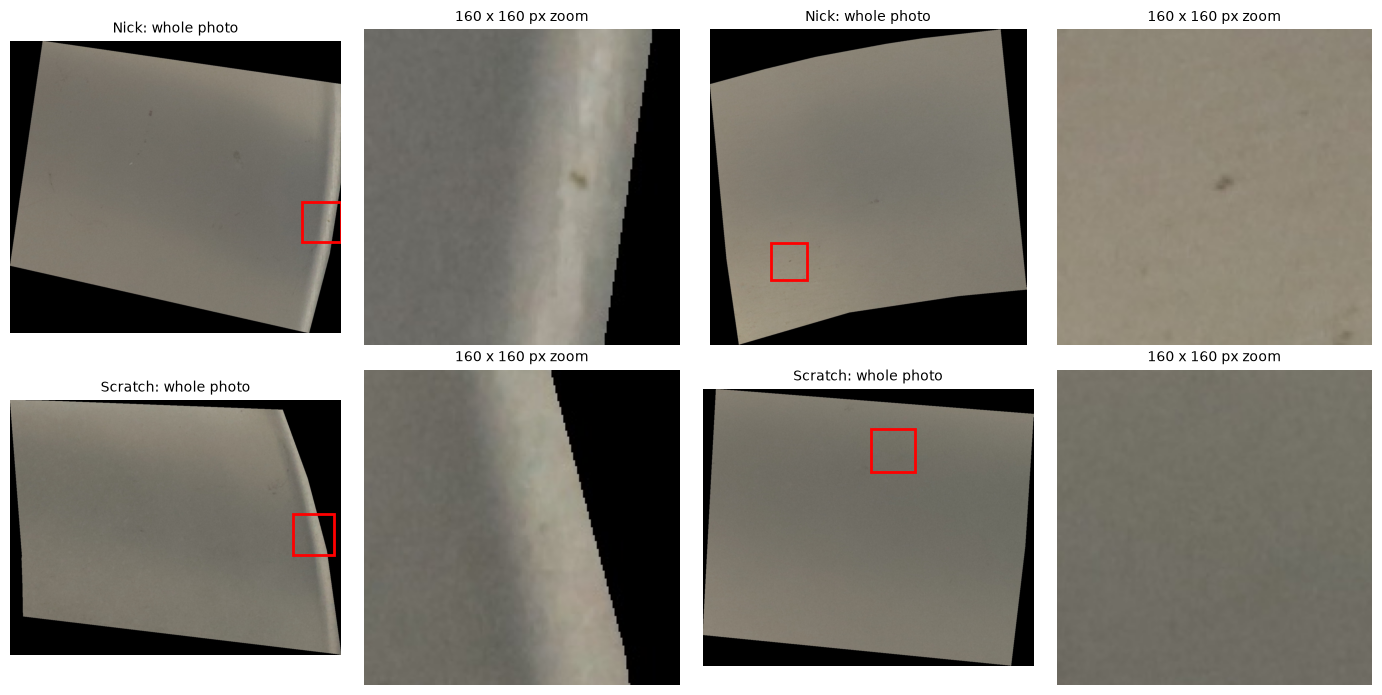

In [4]:
def strongest_patch(img, size=160):
    g = np.asarray(img.convert("L"), dtype=np.float32)
    gy, gx = np.gradient(g)
    mag = np.hypot(gx, gy)
    mask = g > 40                                          # ignore the black background and the blade outline
    mask = np.minimum.reduce([np.roll(mask, s, axis=a) for a in (0, 1) for s in (-12, 12)])
    mag = np.where(mask, mag, 0)
    k = 24                                                 # sum gradient energy over k x k blocks
    H, W = (mag.shape[0] // k) * k, (mag.shape[1] // k) * k
    blocks = mag[:H, :W].reshape(H // k, k, W // k, k).sum(axis=(1, 3))
    by, bx = np.unravel_index(blocks.argmax(), blocks.shape)
    cy, cx = by * k + k // 2, bx * k + k // 2
    y0, x0 = int(np.clip(cy - size // 2, 0, g.shape[0] - size)), int(np.clip(cx - size // 2, 0, g.shape[1] - size))
    return x0, y0, size

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, c in enumerate([1, 2]):
    for j, i in enumerate(np.where(labels == c)[0][[3, 11]]):
        img = Image.open(files[i]); x0, y0, s = strongest_patch(img)
        ax = axes[row, 2 * j]; ax.imshow(img); ax.add_patch(plt.Rectangle((x0, y0), s, s, fill=False, ec="red", lw=2))
        ax.set_title(f"{CLASSES[c]}: whole photo", fontsize=10); ax.axis("off")
        ax = axes[row, 2 * j + 1]; ax.imshow(img.crop((x0, y0, x0 + s, y0 + s))); ax.set_title("160 x 160 px zoom", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. The locked test set and the cross-validation folds

Each photo is resized once to 224×224 and normalised with the ImageNet channel means and standard deviations (the pre-trained network in section 7 expects exactly that). Then the split: 25 % stratified test set, never touched until section 11, and five stratified folds on the remaining 75 %. Every model below is scored on the same five folds, so their numbers are directly comparable: each development photo gets one **out-of-fold** prediction, made by a model that never saw it.

In [5]:
R = 224
t0 = time.time()
X = np.stack([np.asarray(Image.open(p).convert("RGB").resize((R, R), Image.BILINEAR)) for p in files])
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
XN = (torch.tensor(X).permute(0, 3, 1, 2).float() / 255 - MEAN) / STD
Y = torch.tensor(labels)
print(f"resized {len(X)} photos in {time.time() - t0:.0f} s -> tensor {tuple(XN.shape)}")

dev, test = train_test_split(np.arange(len(labels)), test_size=0.25, stratify=labels, random_state=42)
FOLDS = list(StratifiedKFold(5, shuffle=True, random_state=0).split(dev, labels[dev]))
print("development:", np.bincount(labels[dev]), " test (locked):", np.bincount(labels[test]))
print("validation fold sizes:", [len(va) for _, va in FOLDS])

leaderboard = {}
def macro_f1(y_true, y_pred): return f1_score(y_true, y_pred, average="macro")
def submit(name, oof_proba, test_proba, note=""):
    # record a model: its cross-validated score now, its test probabilities for the final reveal
    leaderboard[name] = dict(cv=macro_f1(labels[dev], oof_proba.argmax(1)), oof=oof_proba, test=test_proba, note=note)
    print(f"{name}: cross-validated macro-F1 = {leaderboard[name]['cv']:.3f}")

resized 400 photos in 10 s -> tensor (400, 3, 224, 224)
development: [152  36 112]  test (locked): [51 12 37]
validation fold sizes: [60, 60, 60, 60, 60]


The `submit` helper is our leaderboard: it stores each model's cross-validated macro-F1 and keeps its test-set probabilities **without scoring them**. They are scored all at once, at the end.

## 5. Baselines

The first entry on any leaderboard should be a model so simple that anything worse is a bug.

* **Majority class**: always answer Good.
* **Hand-made image features + logistic regression**: the kind of rule a vision engineer might have written before deep learning. For each photo we compute colour statistics, a brightness histogram and statistics of the image gradients (scratches and nicks are sharp, local changes in brightness), then fit a logistic regression with balanced class weights.

In [6]:
def handmade_features(img):
    g = img.mean(axis=2)
    on_blade = g > 40
    gy, gx = np.gradient(g)
    mag = np.hypot(gx, gy)[on_blade]
    lap = np.abs(g[2:, 1:-1] + g[:-2, 1:-1] + g[1:-1, 2:] + g[1:-1, :-2] - 4 * g[1:-1, 1:-1])[on_blade[1:-1, 1:-1]]
    hist = np.histogram(g[on_blade], bins=16, range=(0, 255), density=True)[0]
    return np.concatenate([img[on_blade].mean(0), img[on_blade].std(0), hist,
                           np.percentile(mag, [50, 90, 99, 99.9]), [mag.mean(), mag.std()],
                           np.percentile(lap, [50, 90, 99, 99.9]), [on_blade.mean()]])

HF = np.stack([handmade_features(x.astype(np.float32)) for x in X])

def cv_sklearn(make_model, feats):
    # out-of-fold probabilities on the development set + test probabilities of a model fitted on all of it
    oof = np.zeros((len(dev), 3))
    for tr, va in FOLDS:
        oof[va] = make_model().fit(feats[dev[tr]], labels[dev[tr]]).predict_proba(feats[dev[va]])
    return oof, make_model().fit(feats[dev], labels[dev]).predict_proba(feats[test])

majority = np.tile([1.0, 0, 0], (len(dev), 1)), np.tile([1.0, 0, 0], (len(test), 1))
submit("majority class", *majority)
submit("hand-made features + logistic regression",
       *cv_sklearn(lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=5000, class_weight="balanced")), HF))

majority class: cross-validated macro-F1 = 0.224


hand-made features + logistic regression: cross-validated macro-F1 = 0.644


"Always Good" scores 0.22: it gets an F1 of about 0.67 on the Good class and zero on the two defect classes, and macro-F1 averages the three. The hand-made features reach 0.64, so brightness and gradient statistics do carry real signal, but they miss a lot. That is the bar every neural network below has to clear.

## 6. A CNN trained from scratch

Notebook 04 trained CNNs that recognised digits almost perfectly. Can the same recipe learn blades from a few hundred photos? This network has four convolution blocks (two 3×3 convolutions with batch normalisation each, then max-pooling), global average pooling and dropout, about 290,000 parameters, and is trained with the augmentation described in section 3 (random flips, rotations by multiples of 90°, small brightness and contrast changes) and class-weighted cross-entropy.

Training it on all five folds would take long on a CPU, so we spend **one fold** to find out whether it is competitive at all, and compare it with the next model on that same fold.

In [7]:
def augment(xb):
    # orientation carries no information here, so any flip or quarter turn gives a valid new example
    if torch.rand(1) < 0.5: xb = xb.flip(3)
    if torch.rand(1) < 0.5: xb = xb.flip(2)
    xb = torch.rot90(xb, int(torch.randint(0, 4, (1,))), (2, 3))
    n = xb.size(0)
    return xb * (1 + 0.1 * torch.randn(n, 1, 1, 1)) + 0.1 * torch.randn(n, 1, 1, 1)   # contrast and brightness

CLASS_W = torch.tensor(len(dev) / (3 * np.bincount(labels[dev])), dtype=torch.float32)
print("class weights in the loss:", dict(zip(CLASSES, CLASS_W.numpy().round(2))))

def train(model, idx, epochs, lr, size=None, seed=0, frozen=()):
    torch.manual_seed(seed)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(idx) / 32))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.2)   # warm-up + cosine, notebook 03
    rng = np.random.default_rng(seed)
    for ep in range(epochs):
        model.train()
        for m in frozen: m.eval()                  # frozen layers keep their batch-norm statistics
        perm = rng.permutation(idx)
        for i in range(0, len(perm), 32):
            b = perm[i:i + 32]
            xb = XN[b] if size is None else F.interpolate(XN[b], size=size, mode="bilinear", antialias=True)
            loss = F.cross_entropy(model(augment(xb)), Y[b], weight=CLASS_W, label_smoothing=0.05)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model.eval()

def predict(model, idx, size=None, tta=False):
    out = []
    with torch.no_grad():
        for i in range(0, len(idx), 50):
            xb = XN[idx[i:i + 50]]
            if size is not None: xb = F.interpolate(xb, size=size, mode="bilinear", antialias=True)
            views = [torch.rot90(xb.flip(3) if f else xb, k, (2, 3)) for k in range(4) for f in (0, 1)] if tta else [xb]
            out.append(torch.stack([F.softmax(model(v), 1) for v in views]).mean(0))
    return torch.cat(out).numpy()

def block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))

def small_cnn():
    return nn.Sequential(block(3, 16), block(16, 32), block(32, 64), block(64, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 3))

tr0, va0 = FOLDS[0]
t0 = time.time()
scratch = train(small_cnn(), dev[tr0], epochs=25, lr=2e-3, size=128)
p_scratch = predict(scratch, dev[va0], size=128)
print(f"{sum(p.numel() for p in scratch.parameters()):,} parameters, trained in {time.time() - t0:.0f} s")
print(f"fold-1 macro-F1, CNN from scratch at 128 px: {macro_f1(labels[dev[va0]], p_scratch.argmax(1)):.3f}")
print(confusion_matrix(labels[dev[va0]], p_scratch.argmax(1)))

class weights in the loss: {'Good': np.float32(0.66), 'Nick': np.float32(2.78), 'Scratch': np.float32(0.89)}


294,387 parameters, trained in 170 s
fold-1 macro-F1, CNN from scratch at 128 px: 0.530
[[20  6  4]
 [ 1  6  0]
 [ 1 14  8]]


The CNN trained from scratch reaches 0.53 on this fold, below the hand-made features (0.64 averaged over all five folds). Its confusion matrix shows the problem: it learnt that *something* is wrong with many blades, but it calls 14 of the 23 scratches nicks and 6 good blades nicks too. 240 photos are not enough to learn useful edge and texture detectors from zero; notebook 04's digit CNN had about 1,800 images of a far simpler problem. We stop here rather than spend a quarter of an hour on the other four folds: the experiment answered its question.

## 7. Transfer learning, step 1: frozen ImageNet features

A **ResNet-18** (notebook 04 explained residual connections) pre-trained on ImageNet's 1.2 million everyday photos has already learned edges, textures and shapes. Without training it at all, we cut off its final classification layer and use the 512 numbers it produces for each photo as features for a logistic regression. Computing the features is the only expensive step, and it is done once.

In [8]:
resnet = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1).eval()
backbone = nn.Sequential(*list(resnet.children())[:-1], nn.Flatten())
t0 = time.time()
with torch.no_grad():
    EMB = torch.cat([backbone(XN[i:i + 50]) for i in range(0, len(XN), 50)]).numpy()
print(f"ImageNet features {EMB.shape} computed in {time.time() - t0:.0f} s")

frozen_lr = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000, class_weight="balanced"))
submit("frozen ResNet-18 features + logistic regression", *cv_sklearn(frozen_lr, EMB))
oof_frozen = leaderboard["frozen ResNet-18 features + logistic regression"]["oof"]
print(f"same fold as the scratch CNN: macro-F1 {macro_f1(labels[dev[va0]], oof_frozen[va0].argmax(1)):.3f}")

ImageNet features (400, 512) computed in 24 s


frozen ResNet-18 features + logistic regression: cross-validated macro-F1 = 0.757
same fold as the scratch CNN: macro-F1 0.751


Without a single gradient step on blade photos, ImageNet features reach a cross-validated 0.757, well above the hand-made features (0.644), and 0.751 on the fold where the CNN from scratch managed 0.530. Generic features learned from a million everyday photos describe a metal surface better than anything 240 blades can teach from zero: the transfer-learning result of notebook 04, now on real data. The logistic regression is strongly regularised (`C=0.05`) on purpose, since 512 features for 240 photos invite overfitting.

## 8. Transfer learning, step 2: fine-tuning

Frozen features were learned for holiday photos, not for scratches on metal. **Fine-tuning** lets the network adapt: we start from the pre-trained weights and keep training on our photos, with a small learning rate so the useful pre-trained features are adjusted rather than destroyed.

With only 240 training photos per fold, adapting all 11 million weights invites overfitting. A common compromise, used here: **freeze the early layers** (the stem, `layer1` and `layer2`, which detect generic edges and textures that transfer well to any domain, notebook 04) and train only `layer3`, `layer4` and a new 3-class output layer. The frozen layers hold few weights (the count is printed below) but process the largest feature maps, so skipping their gradients also saves time. Every fold trains a fresh copy for 10 epochs with the same augmentation and class weights as before.

In [9]:
def finetune_model():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(512, 3)
    frozen = [m.conv1, m.bn1, m.layer1, m.layer2]
    for part in frozen:
        for p in part.parameters(): p.requires_grad = False
    return m, frozen

m, _ = finetune_model()
print(f"trainable: {sum(p.numel() for p in m.parameters() if p.requires_grad):,} of {sum(p.numel() for p in m.parameters()):,} parameters")

fold_models, oof_ft, oof_ft_tta = [], np.zeros((len(dev), 3)), np.zeros((len(dev), 3))
t0 = time.time()
for k, (tr, va) in enumerate(FOLDS):
    m, frozen = finetune_model()
    train(m, dev[tr], epochs=10, lr=5e-4, seed=k, frozen=frozen)
    oof_ft[va] = predict(m, dev[va])
    oof_ft_tta[va] = predict(m, dev[va], tta=True)
    fold_models.append(m)
    print(f"fold {k + 1}: macro-F1 {macro_f1(labels[dev[va]], oof_ft[va].argmax(1)):.3f}   ({time.time() - t0:.0f} s)")

test_single = predict(fold_models[0], test)
submit("fine-tuned ResNet-18 (one fold model)", oof_ft, test_single)
print(confusion_matrix(labels[dev], oof_ft.argmax(1)))

trainable: 10,494,979 of 11,178,051 parameters


fold 1: macro-F1 0.736   (313 s)


fold 2: macro-F1 0.786   (565 s)


fold 3: macro-F1 0.773   (821 s)


fold 4: macro-F1 0.802   (1082 s)


fold 5: macro-F1 0.777   (1345 s)


fine-tuned ResNet-18 (one fold model): cross-validated macro-F1 = 0.776
[[146   3   3]
 [  0  21  15]
 [  5  17  90]]


Fine-tuning lifts the cross-validated macro-F1 to 0.776. Notice the spread between folds, 0.736 to 0.802: the luck of which 60 photos land in a validation fold moves the score by about as much as the gain over frozen features, something to remember when comparing models.

The confusion matrix shows where the difficulty is. Good blades are almost always recognised (146 of 152), and defective blades are rarely called Good (5 of 148). The hard part is telling the two defects apart: 15 nicks are called scratches and 17 scratches are called nicks. For the accept/reject decision that confusion does not matter; for finding which machine or step causes the defects, it does.

## 9. Ensembling and test-time augmentation

Two tricks that appear in nearly every winning competition solution, and that are cheap once the models exist:

* **Ensembling.** Cross-validation trained five models, each on a different 80 % of the development set. Averaging their predicted probabilities on new photos cancels part of their individual errors. No extra training needed.
* **Test-time augmentation (TTA).** Show each photo to the model in all 8 orientations (4 quarter turns, each with and without a mirror flip) and average the 8 predictions. Since orientation means nothing here, the 8 answers should agree; where they do not, averaging smooths out the noise.

TTA can be checked with cross-validation (each fold model on its own validation photos, as computed above). The 5-model ensemble cannot, since every development photo was in the training set of four of the five models, so its benefit is only visible on the test set. That is a judgement call made before the reveal, based on how reliably ensembling helps in practice; the final leaderboard will tell us whether it paid off.

In [10]:
print(f"one model, plain:  CV macro-F1 {macro_f1(labels[dev], oof_ft.argmax(1)):.3f}")
print(f"one model, TTA x8: CV macro-F1 {macro_f1(labels[dev], oof_ft_tta.argmax(1)):.3f}")

t0 = time.time()
test_ens = np.mean([predict(m, test, tta=True) for m in fold_models], axis=0)
print(f"ensemble of 5 x 8 views on the {len(test)} test photos: {time.time() - t0:.0f} s")
submit("fine-tuned ResNet-18, 5-model ensemble + TTA", oof_ft_tta, test_ens, note="CV column: one model + TTA")

one model, plain:  CV macro-F1 0.776
one model, TTA x8: CV macro-F1 0.777


ensemble of 5 x 8 views on the 100 test photos: 225 s
fine-tuned ResNet-18, 5-model ensemble + TTA: cross-validated macro-F1 = 0.777


TTA moves the cross-validated score by 0.001, which is nothing. That is an honest and explainable result: the model was trained with exactly these flips and rotations, so it already gives almost the same answer in every orientation, and averaging eight near-identical answers changes little. TTA helps most when training did not cover the symmetry. It stays in the final submission because it does no harm; the ensemble is the bigger bet.

## 10. From probabilities to a decision on the line

The line does not need to know whether a defect is a nick or a scratch to reject the part; that distinction matters for root-cause analysis later. The reject decision is binary: **reject when P(defect) = P(Nick) + P(Scratch) is above a threshold**. The default threshold, 0.5, treats both mistakes as equally bad, but they are not. An escaped defect can mean a returned shipment or a failure in service; a false reject costs a second look by the inspector.

So we pick the threshold on the development set's out-of-fold predictions: the **highest** threshold whose escape rate stays at or below a target, here 2 %. The curve below shows the trade-off.

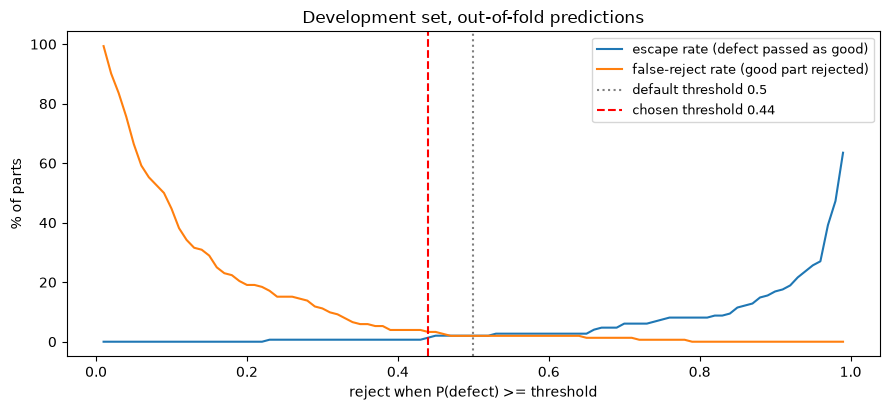

threshold 0.50: escape rate 2.0%, false-reject rate 2.0%
threshold 0.44: escape rate 1.4%, false-reject rate 3.3%


In [11]:
def rates(p_defect, is_defect, t):
    reject = p_defect >= t
    return np.mean(~reject[is_defect]), np.mean(reject[~is_defect])     # escape rate, false-reject rate

p_dev = 1 - oof_ft_tta[:, 0]
is_def_dev = labels[dev] > 0
grid = np.linspace(0.01, 0.99, 99)
esc, fr = np.array([rates(p_dev, is_def_dev, t) for t in grid]).T
TARGET = 0.02
THRESH = grid[esc <= TARGET].max()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(grid, esc * 100, label="escape rate (defect passed as good)")
ax.plot(grid, fr * 100, label="false-reject rate (good part rejected)")
ax.axvline(0.5, color="grey", ls=":", label="default threshold 0.5")
ax.axvline(THRESH, color="red", ls="--", label=f"chosen threshold {THRESH:.2f}")
ax.set_xlabel("reject when P(defect) >= threshold"); ax.set_ylabel("% of parts"); ax.legend(fontsize=9)
ax.set_title("Development set, out-of-fold predictions"); plt.tight_layout(); plt.show()
for t in (0.5, THRESH):
    e, f = rates(p_dev, is_def_dev, t)
    print(f"threshold {t:.2f}: escape rate {e:.1%}, false-reject rate {f:.1%}")

At the default threshold of 0.50, 2.0 % of the defective development photos escape (3 of 148), just over the 2 % target. Lowering the threshold to 0.44 brings escapes down to 1.4 % (2 of 148) and raises false rejects from 2.0 % to 3.3 % (from 3 to 5 of 152 good parts). The curves are flat in between because most photos get confident probabilities; only a handful sit in the middle.

Keep the resolution of the data in mind: with 148 defective photos, each one is worth 0.7 percentage points of escape rate, so a 2 % target is close to what this dataset can measure. A real line would set the threshold on thousands of parts and revisit it as data accumulates.

## 11. Opening the test set: the final leaderboard

Every decision is now frozen: the models, the ensemble, the threshold. Time to score the test set, once.

In [12]:
rows = []
for name, r in leaderboard.items():
    rows.append((name, r["cv"], macro_f1(labels[test], r["test"].argmax(1)), r["note"]))
print(f"{'model':52s} {'CV macro-F1':>12s} {'TEST macro-F1':>14s}")
for name, cv, te, note in rows:
    print(f"{name:52s} {cv:12.3f} {te:14.3f}   {note}")

# how much of the gap between models is luck of the draw? resample the 100 test photos with replacement
rng = np.random.default_rng(0)
boot = rng.integers(0, len(test), size=(2000, len(test)))
def boot_f1(proba): return np.array([macro_f1(labels[test][b], proba[b].argmax(1)) for b in boot])
print(f"\n{'bootstrap over the test photos':52s} {'90% interval':>27s}")
scores = {}
for name, r in leaderboard.items():
    scores[name] = boot_f1(r["test"])
    lo, hi = np.percentile(scores[name], [5, 95])
    print(f"{name:52s} {lo:12.3f} - {hi:.3f}")
diff = scores["fine-tuned ResNet-18, 5-model ensemble + TTA"] - scores["frozen ResNet-18 features + logistic regression"]
print(f"ensemble minus frozen features: 90% interval {np.percentile(diff, 5):+.3f} to {np.percentile(diff, 95):+.3f}, "
      f"ensemble ahead in {np.mean(diff > 0):.0%} of resamples")

final = test_ens.argmax(1)
print("\nfinal model, test confusion matrix (rows = truth, columns = prediction):")
print("            " + "  ".join(f"{c:>7s}" for c in CLASSES))
for c, row in zip(CLASSES, confusion_matrix(labels[test], final)):
    print(f"{c:10s}  " + "  ".join(f"{v:7d}" for v in row))

is_def_test = labels[test] > 0
for t in (0.5, THRESH):
    e, f = rates(1 - test_ens[:, 0], is_def_test, t)
    print(f"accept/reject at threshold {t:.2f}: escapes {e:.1%} ({int(round(e * is_def_test.sum()))} of {is_def_test.sum()} defective), "
          f"false rejects {f:.1%} ({int(round(f * (~is_def_test).sum()))} of {(~is_def_test).sum()} good)")

model                                                 CV macro-F1  TEST macro-F1
majority class                                              0.224          0.225   
hand-made features + logistic regression                    0.644          0.678   
frozen ResNet-18 features + logistic regression             0.757          0.803   
fine-tuned ResNet-18 (one fold model)                       0.776          0.714   
fine-tuned ResNet-18, 5-model ensemble + TTA                0.777          0.788   CV column: one model + TTA

bootstrap over the test photos                                      90% interval


majority class                                              0.200 - 0.247


hand-made features + logistic regression                    0.585 - 0.760


frozen ResNet-18 features + logistic regression             0.716 - 0.879


fine-tuned ResNet-18 (one fold model)                       0.624 - 0.794


fine-tuned ResNet-18, 5-model ensemble + TTA                0.695 - 0.866
ensemble minus frozen features: 90% interval -0.084 to +0.052, ensemble ahead in 35% of resamples

final model, test confusion matrix (rows = truth, columns = prediction):
               Good     Nick  Scratch
Good             47        0        4
Nick              0        7        5
Scratch           0        5       32
accept/reject at threshold 0.50: escapes 0.0% (0 of 49 defective), false rejects 7.8% (4 of 51 good)
accept/reject at threshold 0.44: escapes 0.0% (0 of 49 defective), false rejects 9.8% (5 of 51 good)


The reveal holds a surprise, and it is the most useful lesson of the capstone. The single fine-tuned model drops from 0.776 in cross-validation to 0.714 on the test set, while the frozen features rise from 0.757 to 0.803 and finish ahead of our final submission, the ensemble (0.788). Competitors know this as a **leaderboard shake-up**.

The bootstrap shows why it happened. Resampling the 100 test photos gives every model a 90 % interval about 0.17 wide, and the difference between the ensemble and the frozen features ranges from -0.084 to +0.052, with the ensemble ahead in only 35 % of the resamples. With 12 nicks in the test set, one nick more or less correctly classified moves macro-F1 by two to three points. This test set cannot tell those two models apart. What it can tell is that both are far better than the majority class, and very likely better than the hand-made features, whose interval overlaps theirs only at its top end.

Should we now switch to the frozen-feature model? No. Picking the winner *by its test score* would turn the test set into one more development set, and the score we report would become an optimistic guess instead of an honest estimate. The process (choose with cross-validation, report on the locked test set) is what makes the number trustworthy, even when it is not the number we hoped for.

For the line itself the result is good news: at either threshold, **none of the 49 defective test parts would have been shipped**. The price is 4 or 5 good parts rejected out of 51 (7.8 % or 9.8 %), more than the development estimate of 3.3 %; with 51 good parts, each one is worth 2 points.

## 12. Where does the model look, and what does it get wrong?

A high score is not enough to trust a model on a production line: we want to know that it rejects parts *because of the defect*, not because of something that happens to correlate with defects in this dataset (the lighting on the day the scratched blades were photographed, a fixture visible in the background...). That failure is called **shortcut learning**, and it is common in industrial datasets collected in batches.

**Grad-CAM** (Selvaraju et al., 2017) gives a quick look. Take the last convolutional feature maps of the network (`layer4`, 7×7 positions × 512 channels), weight each channel by how much the predicted class score increases when that channel increases (its average gradient), sum, and keep the positive part. The result is a coarse map of the regions that pushed the decision towards that class, upsampled onto the photo.

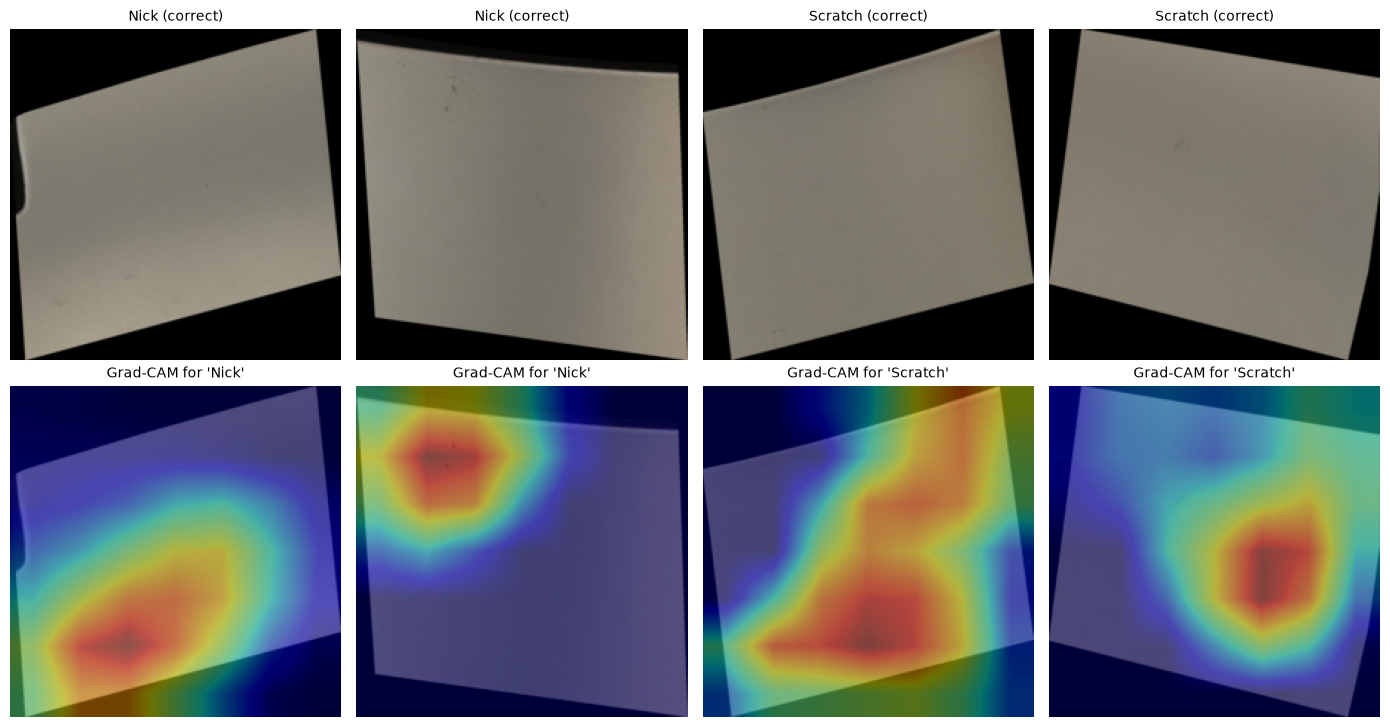

14 of 100 test photos misclassified:
  truth Nick     -> predicted Scratch    P(Good, Nick, Scratch) = (0.01, 0.24, 0.75)
  truth Nick     -> predicted Scratch    P(Good, Nick, Scratch) = (0.08, 0.10, 0.81)
  truth Nick     -> predicted Scratch    P(Good, Nick, Scratch) = (0.19, 0.24, 0.58)
  truth Scratch  -> predicted Nick       P(Good, Nick, Scratch) = (0.00, 0.87, 0.13)
  truth Good     -> predicted Scratch    P(Good, Nick, Scratch) = (0.25, 0.21, 0.54)
  truth Scratch  -> predicted Nick       P(Good, Nick, Scratch) = (0.42, 0.46, 0.12)
  truth Good     -> predicted Scratch    P(Good, Nick, Scratch) = (0.16, 0.37, 0.47)
  truth Good     -> predicted Scratch    P(Good, Nick, Scratch) = (0.38, 0.21, 0.41)
  truth Scratch  -> predicted Nick       P(Good, Nick, Scratch) = (0.01, 0.61, 0.39)
  truth Nick     -> predicted Scratch    P(Good, Nick, Scratch) = (0.05, 0.21, 0.74)
  truth Scratch  -> predicted Nick       P(Good, Nick, Scratch) = (0.02, 0.85, 0.13)
  truth Scratch  -> predicte

In [13]:
def grad_cam(model, x, cls):
    feats = {}
    h1 = model.layer4.register_forward_hook(lambda m, i, o: feats.__setitem__("a", o))
    h2 = model.layer4.register_full_backward_hook(lambda m, gi, go: feats.__setitem__("g", go[0]))
    model.zero_grad()
    model(x)[0, cls].backward()
    h1.remove(); h2.remove()
    w = feats["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear")[0, 0].detach().numpy()
    return cam / (cam.max() + 1e-8)

model = fold_models[0]
for p in model.parameters(): p.requires_grad = True
pred_test = test_ens.argmax(1)
correct = [i for i in range(len(test)) if pred_test[i] == labels[test[i]]]
show = [i for i in correct if labels[test[i]] == 1][:2] + [i for i in correct if labels[test[i]] == 2][:2]   # two nicks, two scratches
wrong = [i for i in range(len(test)) if pred_test[i] != labels[test[i]]]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
for j, i in enumerate(show):
    x = XN[test[i]:test[i] + 1]
    cam = grad_cam(model, x, int(pred_test[i]))
    axes[0, j].imshow(X[test[i]]); axes[0, j].set_title(f"{CLASSES[labels[test[i]]]} (correct)", fontsize=10)
    axes[1, j].imshow(X[test[i]]); axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, j].set_title(f"Grad-CAM for '{CLASSES[pred_test[i]]}'", fontsize=10)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

print(f"{len(wrong)} of {len(test)} test photos misclassified:")
for i in wrong:
    p = test_ens[i]
    print(f"  truth {CLASSES[labels[test[i]]]:8s} -> predicted {CLASSES[pred_test[i]]:8s}   "
          f"P(Good, Nick, Scratch) = ({p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f})")

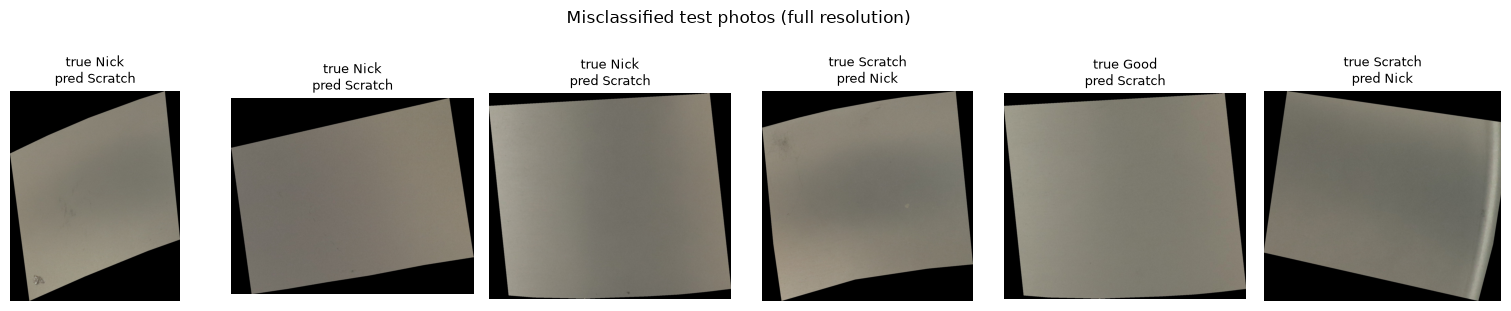

In [14]:
if wrong:
    n = min(len(wrong), 6)
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 3.0), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n]):
        ax.imshow(Image.open(files[test[i]])); ax.axis("off")
        ax.set_title(f"true {CLASSES[labels[test[i]]]}\npred {CLASSES[pred_test[i]]}", fontsize=9)
    plt.suptitle("Misclassified test photos (full resolution)", y=1.02); plt.tight_layout(); plt.show()

The heatmaps are coarse (each cell of the 7×7 grid covers 32×32 pixels). In the second nick photo the hot spot lands on the dark marks visible at the top left, and in the last scratch photo on a faint mark right of centre: there the model is looking at the defect. In the other two photos the map is broad and spreads towards the lower edge of the blade, so they prove less. Grad-CAM is a sanity check, not a proof: at 224×224 pixels most defects are only one or two pixels wide, and a real project would look at many more maps, including those of the good parts.

The error list tells a consistent story. Of the 14 mistakes, 10 swap a nick and a scratch. The other 4 are good blades called Scratch, all with a probability of Good between 0.16 and 0.38: doubtful cases, exactly the ones the three-way routing below sends to a person. No defective blade was called Good. Even in the full-resolution photos above, the defects are hard to find at a glance, which shows how much detail the 224×224 version loses. With only 48 nicks in total, collecting more nick photos (and double-checking the labels of the confusing ones) is the most valuable next step, ahead of any change to the model.

## 13. From notebook to production line

A competition ends with the leaderboard. A real inspection project is only starting. The questions that decide whether the model is used:

* **Speed.** The line needs an answer before the next part arrives. The cell below times the model on this CPU.
* **What to do with doubtful parts.** Probabilities give a natural three-way split: confident Good is shipped, confident defect is rejected, and anything in between goes to the human inspector. The inspector's workload drops to the doubtful fraction, and every one of those decisions becomes a new labelled example.
* **More data where it hurts.** With only 48 nicks, every extra nick photo is worth far more than another good one. Error analysis (section 12) says which kind of photo to collect next.
* **Drift.** A new camera, a different light, a new supplier of raw material: any of these can silently change the photos. Log the model's average P(defect) and the share of doubtful parts per shift; a sudden change is the first sign that the model needs checking.
* **Resolution.** We threw away 95 % of the pixels to fit 224×224. Cutting each photo into tiles at full resolution, or detecting defects with a segmentation model (notebook 09) instead of classifying whole photos, are the natural next steps when the error analysis shows small defects being missed.

In [15]:
one = XN[:1]
with torch.no_grad():
    for _ in range(3): model(one)                                     # warm-up
    t0 = time.time(); [model(one) for _ in range(20)]; single = (time.time() - t0) / 20
t0 = time.time(); predict(model, np.array([0]), tta=True); tta_time = time.time() - t0
size_mb = sum(p.numel() for p in model.parameters()) * 4 / 1e6
print(f"one model, one photo: {single * 1000:.0f} ms;  with 8-view TTA: {tta_time * 1000:.0f} ms;  "
      f"5-model ensemble + TTA: about {5 * tta_time:.1f} s per photo")
print(f"model size: {size_mb:.0f} MB per model (float32)")

p_def = 1 - test_ens[:, 0]
low, high = 0.15, 0.85
auto_good, auto_reject = p_def < low, p_def >= high
doubtful = ~auto_good & ~auto_reject
print(f"\nthree-way routing of the {len(test)} test parts (P(defect) < {low} ship, >= {high} reject, otherwise human):")
print(f"  shipped automatically:  {auto_good.sum():3d}, of which defective: {(auto_good & is_def_test).sum()}")
print(f"  rejected automatically: {auto_reject.sum():3d}, of which good: {(auto_reject & ~is_def_test).sum()}")
print(f"  sent to the inspector:  {doubtful.sum():3d} ({doubtful.mean():.0%} of the workload)")

one model, one photo: 62 ms;  with 8-view TTA: 544 ms;  5-model ensemble + TTA: about 2.7 s per photo
model size: 45 MB per model (float32)

three-way routing of the 100 test parts (P(defect) < 0.15 ship, >= 0.85 reject, otherwise human):
  shipped automatically:   28, of which defective: 0
  rejected automatically:  43, of which good: 0
  sent to the inspector:   29 (29% of the workload)


One model answers in well under a tenth of a second per photo on a laptop CPU, fast enough for a line that produces a part every few seconds. The full ensemble with 8-view TTA takes about 3 seconds per photo, which may not fit the cycle time; since TTA added nothing measurable, a team would ship the five models without TTA (five times one model) or a single model on a small edge computer.

The three-way routing is where the model pays for itself. On the 100 test parts, 71 are decided automatically with **no mistakes** (28 shipped, 43 rejected) and 29 go to the inspector. On this sample that is a 71 % cut in the inspector's workload, with the doubtful cases still seen by a person. The bands (0.15 and 0.85) were set by hand here; in a real project they would be chosen on the development set the same way as the threshold in section 10.

## Key takeaways

* **Fix the metric and lock the test set before you start.** Macro-F1 for the imbalanced three-class problem, escape and false-reject rates for the decision the line actually makes. Every choice was made with cross-validation; the test set was scored once.
* **Always beat a baseline.** "Always Good" and hand-made features set the floor and told us how hard the problem really is.
* **With a few hundred real images, transfer learning wins.** A network trained from scratch could not learn enough from 240 photos; ImageNet features worked out of the box, and fine-tuning the upper layers with augmentation improved them in cross-validation.
* **Competition tricks are cheap**: cross-validated fold models become an ensemble for free, and test-time augmentation exploits a symmetry of the problem (orientation does not matter). Measure whether they help: here TTA added nothing.
* **A small test set is noisy.** With 100 photos, differences of a few macro-F1 points between models are within the noise; the bootstrap makes that visible. Do not switch models after looking at the test set.
* **A probability is not a decision.** The reject threshold encodes what each mistake costs, and the same model can be tuned for few escapes or few false rejects, or route doubtful parts to a person.
* **Look at what the model looks at.** Grad-CAM and the list of errors are how you find shortcuts, label mistakes and the data you should collect next.

## Exercises

1. Change `R` to 160 and to 288 (the fine-tuning cell takes about twice as long at 288). How does the cross-validated macro-F1 react? Which class benefits most from more pixels?
2. Crop each photo to the bounding box of the blade (the pixels brighter than 40) before resizing. Does using the pixels on the blade instead of the black background help?
3. Unfreeze `layer2` as well, then fine-tune all layers. Compare the cross-validated scores and the training time. At what point does adapting more weights start to hurt with this little data?
4. Remove the class weights from the loss. What happens to the Nick column of the confusion matrix?
5. Set the escape-rate target to 0 % on the development set. What does that do to the false-reject rate, and how stable is that threshold on the test set?
6. Replace ResNet-18 by `torchvision.models.mobilenet_v3_small` (pre-trained). How much faster is it per photo, and how much accuracy does it cost?
7. Combine models: average the probabilities of the frozen-feature logistic regression and the fine-tuned ensemble. Is the combination better than either one on cross-validation?